# Lab 7 – Go-to-goal: the 50 trajectory

Planned vs simulator vs real-robot odometry. The bundled simulator log is from TRIK Studio's runner. Real data is pending; no real results are invented. Coordinates: cm. Time: ms.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Positive y points down in the working simulator display.
wp = np.array([[0,0],[-40,0],[-40,40],[0,40],[0,80],[-40,80],
               [20,80],[60,80],[60,0],[20,0],[20,80]], dtype=float)
paths = {"simulator": "odometry_gtg_sim.txt",
         "real": "odometry_gtg_real.txt",
         "real repeat": "odometry_gtg_real_repeat.txt"}
runs = {}
for label, filename in paths.items():
    if not Path(filename).exists():
        print(f"{label}: not supplied")
        continue
    data = np.loadtxt(filename, delimiter=",", ndmin=2)
    if data.shape[1] != 3 or len(data) < 2 or not np.isfinite(data).all():
        raise ValueError(f"Invalid x,y,time log: {filename}")
    if np.any(np.diff(data[:,2]) < 0):
        raise ValueError(f"Time goes backwards: {filename}; use one run per file")
    runs[label] = data
    print(f"{label}: {len(data)} rows, final time {data[-1,2]/1000:.2f} s")
if not runs:
    raise FileNotFoundError("Place at least one log next to this notebook.")

simulator: 16623 rows, final time 166.23 s
real: 1336 rows, final time 65.92 s
real repeat: not supplied


## 1. Trajectories
The gray dashed segment is the pen-up transfer. Logs show the whole driven path, including that transfer. The coordinates come from encoders, not an independent tracking system.

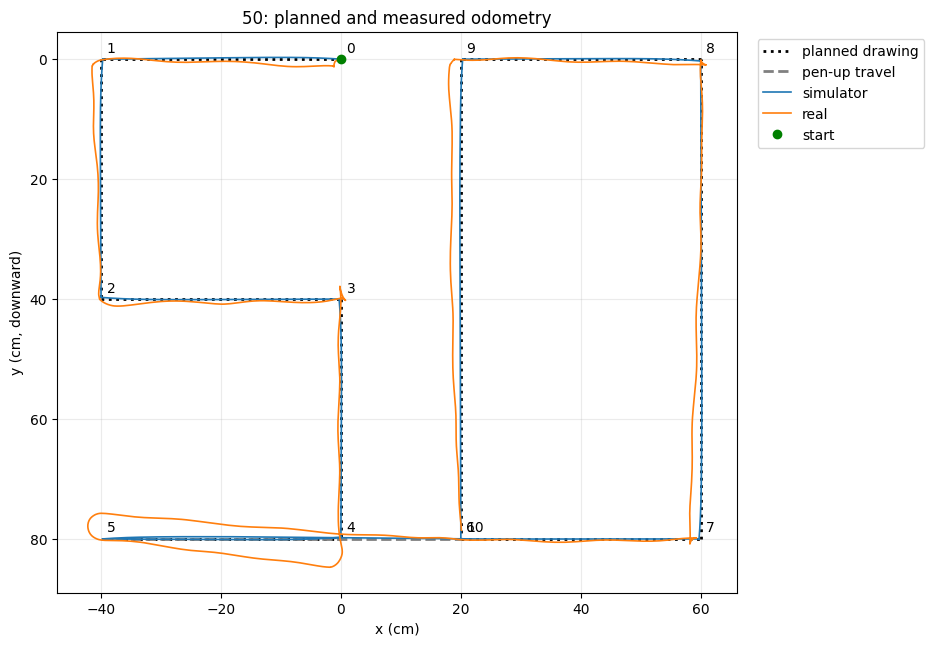

In [2]:
fig, ax = plt.subplots(figsize=(9,7))
for j in range(len(wp)-1):
    gap = (j == 5)
    ax.plot(wp[j:j+2,0], wp[j:j+2,1], "--" if gap else ":",
            color="gray" if gap else "black", linewidth=2,
            label="planned drawing" if j==0 else ("pen-up travel" if gap else None))
for label, data in runs.items():
    ax.plot(data[:,0], data[:,1], linewidth=1.2, label=label)
for j, (x,y) in enumerate(wp):
    ax.annotate(str(j), (x,y), xytext=(4,5), textcoords="offset points")
ax.plot(0,0,"go",label="start")
ax.set_aspect("equal"); ax.invert_yaxis(); ax.grid(alpha=.25)
ax.set(xlabel="x (cm)",ylabel="y (cm, downward)",title="50: planned and measured odometry")
ax.legend(loc="upper left",bbox_to_anchor=(1.02,1)); plt.tight_layout()
plt.show()

## 2. Corner proximity and timing
Minimum recorded distance to each planned waypoint. A repeated/nearby path can also pass a corner, so this is not a sequential arrival detector. It measures odometry proximity, not ground-truth physical error.

In [3]:
errors = {}
print("Run                 duration(s)  median sample(ms)  max corner miss(cm)")
for label, data in runs.items():
    errors[label] = np.min(np.linalg.norm(data[:,None,:2]-wp[None,1:,:],axis=2),axis=0)
    duration = (data[-1,2]-data[0,2])/1000
    median_dt = np.median(np.diff(data[:,2]))
    print(f"{label:20s} {duration:10.2f} {median_dt:18.2f} {errors[label].max():20.3f}")
print("\nTarget   " + "  ".join(f"{k:>14s}" for k in errors))
for i in range(10):
    print(f"{i:6d}   " + "  ".join(f"{v[i]:14.3f}" for v in errors.values()))

Run                 duration(s)  median sample(ms)  max corner miss(cm)
simulator                166.22              10.00                0.292
real                      65.86              48.00                0.701

Target        simulator            real
     0            0.254           0.136
     1            0.259           0.190
     2            0.282           0.131
     3            0.202           0.150
     4            0.261           0.194
     5            0.065           0.224
     6            0.261           0.701
     7            0.287           0.125
     8            0.292           0.186
     9            0.065           0.224


## 3. Distance from the planned path
For each sample, find the nearest point on any planned segment, including pen-up travel. This detects geometric deviation but does not check whether the segments were visited in the correct order.

simulator: RMS path deviation 0.098 cm; max 0.371 cm
real: RMS path deviation 1.562 cm; max 4.720 cm


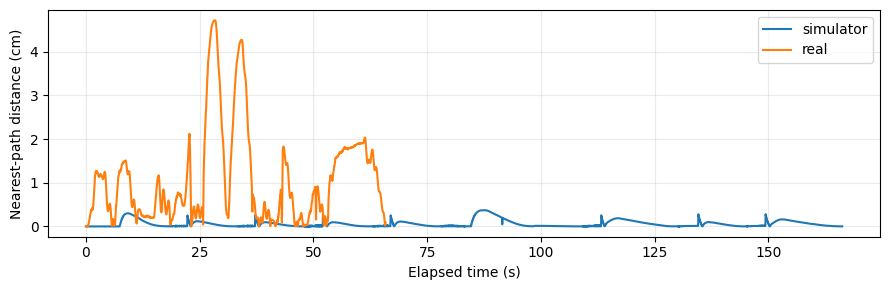

In [4]:
def path_distance(points, route):
    a, b = route[:-1], route[1:]
    v = b-a
    t = np.sum((points[:,None,:]-a[None,:,:])*v[None,:,:],axis=2)/np.sum(v*v,axis=1)
    nearest = a[None,:,:] + np.clip(t,0,1)[:,:,None]*v[None,:,:]
    return np.min(np.linalg.norm(points[:,None,:]-nearest,axis=2),axis=1)
fig, ax = plt.subplots(figsize=(9,3))
for label, data in runs.items():
    err = path_distance(data[:,:2],wp)
    ax.plot((data[:,2]-data[0,2])/1000,err,label=label)
    print(f"{label}: RMS path deviation {np.sqrt(np.mean(err**2)):.3f} cm; max {err.max():.3f} cm")
ax.set(xlabel="Elapsed time (s)",ylabel="Nearest-path distance (cm)")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()

## 4. Discussion

The simulator uses a 3 mm arrival radius and stops forward motion while it aligns
with the next target. Small corner offsets remain because arrival uses a tolerance.
The real version uses the source robot's dimensions and swapped ports, a 1.5 cm
arrival radius, lower steering gain and a forward-command floor as starting settings.

**Real measurements are still pending.** After collecting them, compare the tables
and plots above. Record the actual geometry, motor mapping, battery condition and
any tuning changes. Explain observed differences using evidence from those runs.
A longer actual loop interval, motor lag, wheel slip or incorrect dimensions can
change the trajectory; this notebook does not separately identify those causes.

An external endpoint measurement or overhead video would help assess odometry drift.
Do not treat the encoder-derived path as independent proof that the physical robot
followed that path exactly. A second run is useful for assessing repeatability.
